<a href="https://colab.research.google.com/github/cpoiato/HYDROSIGHT/blob/main/02_eda_pipes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [79]:
!git clone https://github.com/cpoiato/HYDROSIGHT.git /content/HYDROSIGHT

fatal: destination path '/content/HYDROSIGHT' already exists and is not an empty directory.


In [80]:
%cd /content/HYDROSIGHT
!git pull --ff-only

/content/HYDROSIGHT
Already up to date.


In [132]:
%cd /content/HYDROSIGHT/src/hydrosight/eda/notebooks

/content/HYDROSIGHT/src/hydrosight/eda/notebooks


In [81]:
from pathlib import Path

repo_path = Path("/content/HYDROSIGHT")

print("Repository folder exists:", repo_path.exists())
print("Git metadata exists:", (repo_path / ".git").exists())
print("Current directory:", Path.cwd())

Repository folder exists: True
Git metadata exists: True
Current directory: /content/HYDROSIGHT


In [82]:
from google.colab import drive
import json

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [83]:
import pandas as pd
def analyze_missing_p_zone(df: pd.DataFrame) -> tuple[dict, pd.DataFrame]:
    missing = df[df["p_zone"].isna()].copy()
    known = df[df["p_zone"].notna()].copy()

    def geometry_key(geometry):
        if not isinstance(geometry, dict):
            return None
        return json.dumps(
            geometry,
            sort_keys=True,
            separators=(",", ":")
        )

    missing["_geometry_key"] = missing["multilinestring"].map(geometry_key)
    known["_geometry_key"] = known["multilinestring"].map(geometry_key)


    zone_matches = (
        known.dropna(subset=["_geometry_key"])
        .groupby("_geometry_key")["p_zone"]
        .agg(lambda values: sorted(set(values)))
    )

    matches = missing["_geometry_key"].map(zone_matches)

    unique_matches = matches.map(
        lambda zones: isinstance(zones, list) and len(zones) == 1
    )

    ambiguous_matches = matches.map(
        lambda zones: isinstance(zones, list) and len(zones) > 1
    )


    candidates = missing.loc[unique_matches].copy()
    candidates["suggested_p_zone"] = matches.loc[
        unique_matches
    ].map(lambda zones: zones[0])


    print("\n=== CANDIDATES FOR P_ZONE RECOVERY ===")

    if not candidates.empty:
        print(
            candidates[
                ["globalid", "suggested_p_zone"]
            ].to_string(index=False)
        )
    else:
        print("No exact geometry matches found.")

    return candidates.drop(columns=["_geometry_key"])


In [84]:
from pathlib import Path
import sys

ROOT_DIR = Path("/content/HYDROSIGHT")
sys.path.insert(0, str(ROOT_DIR / "src"))
RAW_DIR = ROOT_DIR / "data" / "raw" / "pipes"
REPORT_DIR = ROOT_DIR / "reports" / "eda" / "results"
FIGURES_DIR = ROOT_DIR / "reports" / "eda" / "figures"
HTML_REPORT = ROOT_DIR / "reports" / "eda" / "pipes_eda_report.html"
PROCESSED_DIR = ROOT_DIR / "data" / "processed" / "water_breaks"

assert RAW_DIR.exists(), f"Folder not found: {RAW_DIR}"
assert RAW_DIR.exists(), f"Folder not found: {RAW_DIR}"

print("Project:", ROOT_DIR)
print("Raw data:", RAW_DIR)

print("\nAvailable pipe files:")
for file in sorted(RAW_DIR.glob("*.jsonl")):
    print(file.name)

Project: /content/HYDROSIGHT
Raw data: /content/HYDROSIGHT/data/raw/pipes

Available pipe files:
public_water_mains_20261024T153107Z.jsonl


In [85]:
import pandas as pd
from IPython.display import display


files = sorted(RAW_DIR.glob("public_water_mains_*.jsonl"))

assert files, "No pipe snapshots found."

latest_file = files[-1]

df = pd.read_json(latest_file, lines=True)
df.shape

(60740, 8)

### On remarke que le dataset contient 8 caracteristiques et 60740 observations

In [86]:
display("Dataset Information")
df.info()

'Dataset Information'

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60740 entries, 0 to 60739
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   p_zone           59274 non-null  object 
 1   status_ind       60740 non-null  object 
 2   length           60740 non-null  float64
 3   diam             60740 non-null  int64  
 4   material         60740 non-null  object 
 5   year             60740 non-null  int64  
 6   globalid         60740 non-null  object 
 7   multilinestring  60740 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 3.7+ MB


In [87]:
display("Sample Data")
df.sample(20)

'Sample Data'

,p_zone,status_ind,length,diam,material,year,globalid,multilinestring
50228,WEST CALGARY,ACTIVE,127.4888,400,PVC,1997,d6eaca42-3979-403c-b2f3-b9d21c6746b3,"{'type': 'MultiLineString', 'coordinates': [[[..."
29903,NORTH HILL,ACTIVE,28.2629,750,CON,1976,95fb76be-6efe-45e6-9c6e-006f4a6fa6a6,"{'type': 'MultiLineString', 'coordinates': [[[..."
33516,NOSE HILL EAST,ACTIVE,5.7516,300,PVC,2015,15455497-cef0-4eb3-a880-80b7aec5a862,"{'type': 'MultiLineString', 'coordinates': [[[..."
39633,NORTH HILL,ACTIVE,62.2342,50,CU,1948,09902c7c-e9f2-4725-a7e4-8ec196cb4783,"{'type': 'MultiLineString', 'coordinates': [[[..."
47335,OGDEN,ACTIVE,101.9377,250,PVC,1986,b806d329-2a90-4af5-8f5d-daa9dccf7431,"{'type': 'MultiLineString', 'coordinates': [[[..."
46198,NORTH HILL,ACTIVE,11.1892,300,YDI,1981,47e3383a-f5c1-47b1-a5c0-6008abfc0c85,"{'type': 'MultiLineString', 'coordinates': [[[..."
17254,GLENMORE,ACTIVE,82.2127,250,PVC,2018,ccb25cec-a4f2-40e1-b201-518bd1d4461a,"{'type': 'MultiLineString', 'coordinates': [[[..."
27462,BANKVIEW,ACTIVE,7.8867,150,CI,1948,1519525c-627b-44e4-a030-338cf9b125d5,"{'type': 'MultiLineString', 'coordinates': [[[..."
13355,GLENMORE,ACTIVE,226.0990,150,YDI,1983,5f0c2257-734f-4f74-aaea-f88bcc1bee01,"{'type': 'MultiLineString', 'coordinates': [[[..."
60252,OGDEN,ACTIVE,59.6737,250,PVC,2023,9c54bbc6-ac19-48e9-b025-a0deedec1520,"{'type': 'MultiLineString', 'coordinates': [[[..."


In [88]:
display("Data Description")
df.describe()

'Data Description'

,length,diam,year
count,60740.000000,60740.000000,60740.000000
mean,89.212361,246.532746,1988.634425
std,113.650621,158.465985,21.907641
min,0.017300,0.000000,1900.000000
25%,11.759475,150.000000,1975.000000
50%,58.823900,200.000000,1992.000000
75%,119.866850,300.000000,2004.000000
max,3194.111000,1950.000000,2033.000000


In [89]:
categorical_columns = [
        "p_zone",
        "status_ind",
        "material"
    ]

display(df[categorical_columns].describe())

,p_zone,status_ind,material
count,59274,60740,60740
unique,45,3,25
top,GLENMORE,ACTIVE,PVC
freq,13883,60356,33654


In [90]:
display("Percent Missing Values")
missing = df.isna().sum()/df.shape[0]*100
display(missing)

'Percent Missing Values'

,0
p_zone,2.413566
status_ind,0.000000
length,0.000000
diam,0.000000
material,0.000000
year,0.000000
globalid,0.000000
multilinestring,0.000000


il y a 1466 enregistrements sans l'information zone, Avec Exact GeoJSON geometry comparison on essayse d'identifier si c'est possible d'identifier la zone manquante.

In [91]:
missing_zone = analyze_missing_p_zone(df).index


=== CANDIDATES FOR P_ZONE RECOVERY ===
No exact geometry matches found.


### Les enregistrements sans zone n'ont pas de correspondence exact avec les enregistrement qui l'ont. Donc on ne peut pas étableir s'il s'agit d'erreur ou si les aqueducs se trouvent à en endroit où il n'y a pas une zone établie. La décision pour l'intant est de conserver ces enregistrement et remplacer les null par "Undefined".

In [92]:
# Replace missing pressure zones
df["p_zone"] = df["p_zone"].fillna("Undefined")

In [93]:
geometry = df["multilinestring"].iloc[0]

if isinstance(geometry, dict):
        print("Key:", geometry.keys())
        print("Type:", geometry.get("type"))
        print("Coordinates:", geometry.get("coordinates"))

Key: dict_keys(['type', 'coordinates'])
Type: MultiLineString
Coordinates: [[[-114.1993839, 51.0655459], [-114.1994186, 51.0655459]]]


Charger le dataset oficial City Boundary — Calgary Open Data

In [94]:
import geopandas as gpd

# Load Calgary city boundary from the official ArcGIS service
boundary_url = (
    "https://services1.arcgis.com/AVP60cs0Q9PEA8rH/"
    "arcgis/rest/services/City_Boundary/FeatureServer/0/query"
    "?where=1%3D1"
    "&outFields=*"
    "&outSR=4326"
    "&returnGeometry=true"
    "&f=geojson"
)

calgary_boundary = gpd.read_file(boundary_url)

# Validate the boundary geometry
print("Total records:", len(calgary_boundary))
print("CRS:", calgary_boundary.crs)
print("Geometry types:")
print(calgary_boundary.geometry.geom_type.value_counts())
print("Bounds:", calgary_boundary.total_bounds)
print("Valid geometries:", calgary_boundary.geometry.is_valid.sum())

assert (
    not calgary_boundary.empty
    and calgary_boundary.geometry.notna().all()
    and calgary_boundary.geometry.is_valid.all()
    and calgary_boundary.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    ).all()
), "Invalid Calgary boundary geometry"

Total records: 1
CRS: EPSG:4326
Geometry types:
Polygon    1
Name: count, dtype: int64
Bounds: [-114.31580385   50.84282878 -113.85991285   51.21243208]
Valid geometries: 1


In [95]:

from shapely.geometry import shape

# Convert GeoJSON MultiLineString to Shapely geometry
pipes_gdf = gpd.GeoDataFrame(
    df.copy(),
    geometry=df["multilinestring"].apply(
        lambda value: shape(json.loads(value))
        if isinstance(value, str) else shape(value)
    ),
    crs="EPSG:4326"
)

# Validate geometries
print("Total pipes:", len(pipes_gdf))
print("Geometry types:")
print(pipes_gdf.geometry.geom_type.value_counts())
print("Invalid geometries:", (~pipes_gdf.geometry.is_valid).sum())

Total pipes: 60740
Geometry types:
MultiLineString    60740
Name: count, dtype: int64
Invalid geometries: 0


In [96]:
# Align coordinate reference systems
pipes = pipes_gdf.to_crs(calgary_boundary.crs)

# Merge municipal boundary geometries
city_boundary = calgary_boundary.geometry.union_all()

# Classify pipe locations
pipes["boundary_status"] = "outside"

pipes.loc[
    pipes.geometry.intersects(city_boundary),
    "boundary_status"
] = "partially_inside"

pipes.loc[
    pipes.geometry.covered_by(city_boundary),
    "boundary_status"
] = "inside"

# Display validation results
print("Pipe boundary validation results:")
print(pipes["boundary_status"].value_counts())

Pipe boundary validation results:
boundary_status
inside              60718
outside                18
partially_inside        4
Name: count, dtype: int64


In [97]:
# Identify pipes requiring geographic review
pipes_to_review = pipes[
    pipes["boundary_status"].isin(
        ["outside", "partially_inside"]
    )
].copy()

# Display geographic validation details
print("=== PIPES REQUIRING REVIEW ===")
print("Total records:", len(pipes_to_review))
print()

display(
    pipes_to_review[
        ["multilinestring", "boundary_status"]
    ]
)

=== PIPES REQUIRING REVIEW ===
Total records: 22



,multilinestring,boundary_status
1501,"{'type': 'MultiLineString', 'coordinates': [[[...",outside
1502,"{'type': 'MultiLineString', 'coordinates': [[[...",outside
1504,"{'type': 'MultiLineString', 'coordinates': [[[...",partially_inside
15408,"{'type': 'MultiLineString', 'coordinates': [[[...",outside
15409,"{'type': 'MultiLineString', 'coordinates': [[[...",outside
15410,"{'type': 'MultiLineString', 'coordinates': [[[...",outside
15411,"{'type': 'MultiLineString', 'coordinates': [[[...",outside
15412,"{'type': 'MultiLineString', 'coordinates': [[[...",outside
15413,"{'type': 'MultiLineString', 'coordinates': [[[...",outside
15414,"{'type': 'MultiLineString', 'coordinates': [[[...",outside


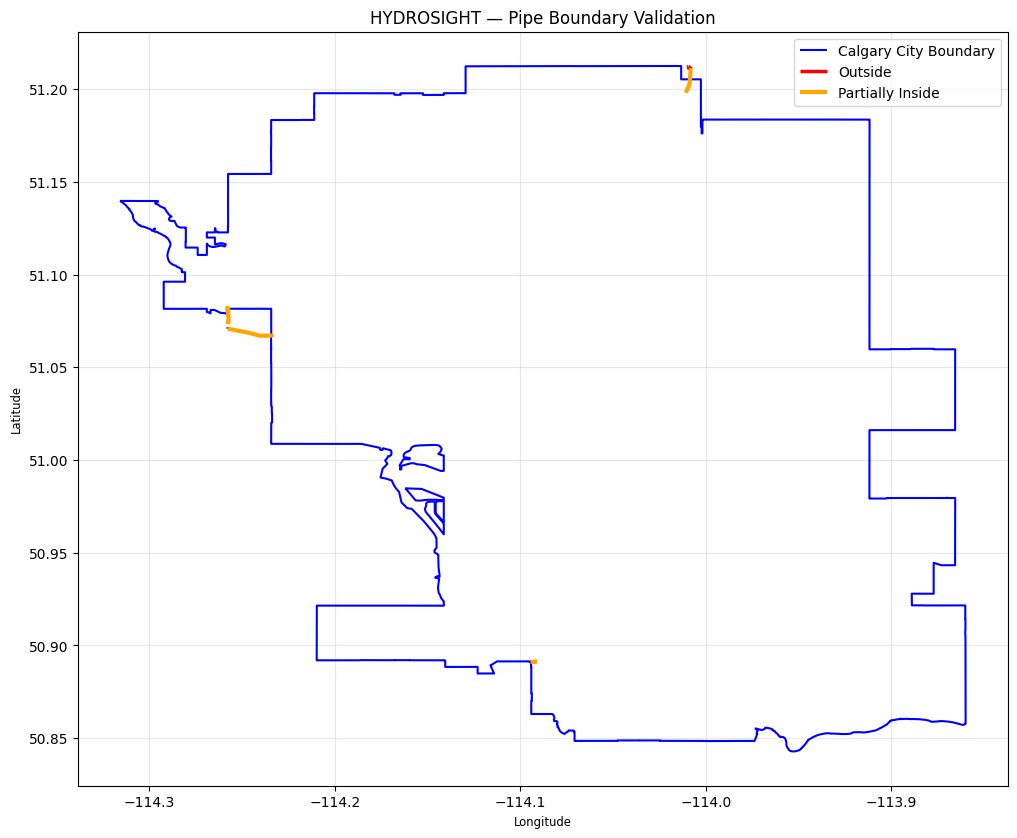

In [98]:
import matplotlib.pyplot as plt

# Create geographic validation plot
fig, ax = plt.subplots(figsize=(12, 12))

# Plot Calgary municipal boundary
calgary_boundary.boundary.plot(
    ax=ax,
    color="blue",
    linewidth=1.5,
    label="Calgary City Boundary"
)

# Plot pipes outside Calgary
pipes_to_review[
    pipes_to_review["boundary_status"] == "outside"
].plot(
    ax=ax,
    color="red",
    linewidth=2.5,
    label="Outside"
)

# Plot pipes partially inside Calgary
pipes_to_review[
    pipes_to_review["boundary_status"] == "partially_inside"
].plot(
    ax=ax,
    color="orange",
    linewidth=3,
    label="Partially Inside"
)

ax.set_title("HYDROSIGHT — Pipe Boundary Validation")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)

plt.show()

In [99]:
# Project geometries to a metric coordinate system
pipes_metric = pipes_to_review.to_crs("EPSG:32611")
boundary_metric = calgary_boundary.to_crs("EPSG:32611")

# Merge municipal boundary geometries
city_polygon = boundary_metric.geometry.union_all()

# Calculate distance to Calgary boundary
pipes_metric["distance_to_city_m"] = (
    pipes_metric.geometry.distance(city_polygon)
)

# Display geographic review results
print("=== PIPE BOUNDARY DISTANCE ANALYSIS ===")

display(
    pipes_metric[
        ["boundary_status", "distance_to_city_m"]
    ].sort_values(
        "distance_to_city_m",
        ascending=True
    )
)

=== PIPE BOUNDARY DISTANCE ANALYSIS ===


,boundary_status,distance_to_city_m
1504,partially_inside,0.000000
15752,partially_inside,0.000000
16454,partially_inside,0.000000
18136,partially_inside,0.000000
16877,outside,0.429279
15408,outside,275.031210
15409,outside,275.033994
15410,outside,275.043782
15411,outside,276.441349
15415,outside,276.441349


In [100]:

files = sorted(PROCESSED_DIR.glob("water_main_breaks_clean_*.jsonl"))

assert files, "No pipe snapshots found."

latest_file = files[-1]


df_breaks = pd.read_json(latest_file,lines=True)
# Select previously identified external pipes
external_pipes = pipes_to_review[
    pipes_to_review["boundary_status"] == "outside"
].copy()

print("External pipes:", len(external_pipes))

# Create spatial geometries for historical breaks
breaks_gdf = gpd.GeoDataFrame(
    df_breaks.copy(),
    geometry=gpd.points_from_xy(
        df_breaks["longitude"],
        df_breaks["latitude"]
    ),
    crs="EPSG:4326"
)

# Project both datasets to a metric coordinate system
external_pipes_metric = external_pipes.to_crs("EPSG:32611")
breaks_metric = breaks_gdf.to_crs("EPSG:32611")

# Find breaks within 10 meters of external pipes
breaks_near_external = gpd.sjoin(
    breaks_metric,
    external_pipes_metric[["geometry"]],
    how="inner",
    predicate="dwithin",
    distance=10
)

# Display results
print("=== EXTERNAL PIPE BREAK VALIDATION ===")
print("External pipes:", len(external_pipes_metric))
print("Matching break records:", breaks_near_external.index.nunique())
print("External pipes with nearby breaks:", breaks_near_external["index_right"].nunique())

display(breaks_near_external)

External pipes: 18
=== EXTERNAL PIPE BREAK VALIDATION ===
External pipes: 18
Matching break records: 0
External pipes with nearby breaks: 0


,break_date,break_type,status,longitude,latitude,geometry,index_right


In [101]:
# Preserve the original dataset and exclude external pipes
external_indices = pipes_metric.index[
    pipes_metric["boundary_status"] == "outside"
]

df_clean = df.drop(index=external_indices).copy()

print("Original pipes:", len(df))
print("Cleaned pipes:", len(df_clean))
print("Excluded pipes:", len(df) - len(df_clean))

Original pipes: 60740
Cleaned pipes: 60722
Excluded pipes: 18


### Validation des conduites situées à l’extérieur des limites municipales de Calgary

Avant de procéder à l’exclusion des conduites situées à l’extérieur des limites administratives de Calgary, une analyse de proximité spatiale a été réalisée à partir des données historiques nettoyées des ruptures de conduites d’eau.

Cette validation visait à déterminer si certaines conduites externes présentaient des ruptures historiquement enregistrées, ce qui pourrait constituer un indice de leur intégration au réseau exploité ou surveillé par la Ville de Calgary.

L’analyse a été effectuée à l’aide d’une jointure spatiale utilisant le système de coordonnées projetées **EPSG:32611 (WGS 84 / UTM Zone 11N)**, avec une tolérance de proximité de **10 mètres**.

**Résultats de la validation :**

- Nombre de conduites situées entièrement à l’extérieur des limites municipales : **18**.
- Nombre de ruptures historiques identifiées à moins de 10 mètres de ces conduites : **0**.
- Nombre de conduites externes associées à au moins une rupture historique à cette distance : **0**.

Ces résultats indiquent qu’aucune rupture historique n’a été identifiée à proximité immédiate des 18 conduites externes, selon les données disponibles et le seuil de distance retenu.

Toutefois, cette absence de correspondance ne permet pas de conclure que ces conduites ne relèvent pas de la responsabilité opérationnelle de Calgary ou qu’elles n’ont jamais subi de défaillance.

### Décision de nettoyage et justification

La décision a été prise d’**exclure les 18 conduites situées entièrement à l’extérieur du territoire municipal** du jeu de données destiné aux analyses du projet HYDROSIGHT.

Cette décision repose principalement sur la délimitation géographique du projet, dont l’objectif est d’évaluer les risques de rupture par secteur à l’intérieur du territoire de Calgary.

L’absence de ruptures historiques détectées à proximité constitue un élément complémentaire de validation, mais ne représente pas le critère principal d’exclusion.

Les **4 conduites traversant les limites municipales** ont été conservées dans leur intégralité afin de préserver leurs géométries originales.

### Résultat final

| Indicateur | Nombre |
|---|---:|
| Conduites initiales | 60 740 |
| Conduites entièrement à l’intérieur | 60 718 |
| Conduites traversant les limites municipales | 4 |
| Conduites exclues | 18 |
| **Total après nettoyage** | **60 722** |

Le jeu de données nettoyé contient ainsi **60 722 conduites**, soit environ **99,97 % des enregistrements initiaux**.

Les données sources originales sont conservées afin de garantir la traçabilité des opérations, la reproductibilité des analyses et la possibilité de réévaluer les décisions de nettoyage.

Cette démarche permet de constituer un ensemble de données géographiquement cohérent avec le périmètre d’étude du projet HYDROSIGHT, sans considérer les conduites exclues comme des erreurs de données avérées.

In [104]:
import json

# Validate duplicate global IDs
duplicate_ids = df_clean[
    df_clean["globalid"].notna()
    & df_clean["globalid"].duplicated(keep=False)
].copy()

# Validate duplicate geometries
geometry_keys = df_clean["multilinestring"].map(
    lambda value: json.dumps(value, sort_keys=True)
)

duplicate_geometries = df_clean[
    geometry_keys.duplicated(keep=False)
].copy()

# Display validation summary
print("=== PIPE DUPLICATE VALIDATION ===")
print("Total records:", len(df_clean))
print("Missing global IDs:", df_clean["globalid"].isna().sum())
print("Records with repeated global IDs:", len(duplicate_ids))
print("Distinct repeated global IDs:", duplicate_ids["globalid"].nunique())
print("Records with repeated geometries:", len(duplicate_geometries))

# Display records requiring investigation
if not duplicate_ids.empty:
    print("\n=== DUPLICATE GLOBAL IDs ===")
    display(duplicate_ids.sort_values("globalid"))

if not duplicate_geometries.empty:
    print("\n=== DUPLICATE GEOMETRIES ===")
    display(duplicate_geometries)

=== PIPE DUPLICATE VALIDATION ===
Total records: 60722
Missing global IDs: 0
Records with repeated global IDs: 0
Distinct repeated global IDs: 0
Records with repeated geometries: 64

=== DUPLICATE GEOMETRIES ===


,p_zone,status_ind,length,diam,material,year,globalid,multilinestring
254,NORTH HILL,ACTIVE,1.0000,300,CIPP,2020,cfb8ccf6-9e7f-49da-ae65-2a5b15f6ae08,"{'type': 'MultiLineString', 'coordinates': [[[..."
14893,NORTH HILL,ACTIVE,57.2038,200,CIPP,2020,f47d2cec-a3b0-4316-8299-ca47d5221105,"{'type': 'MultiLineString', 'coordinates': [[[..."
15513,GREENVIEW,ACTIVE,47.5035,200,PRIM,2017,633550f5-b45d-4f2b-b078-a448283666f9,"{'type': 'MultiLineString', 'coordinates': [[[..."
16284,BIG HILL EAST,ACTIVE,14.5423,250,PRIM,2017,04ded883-8a8f-4ff3-a80f-350fbb68c73d,"{'type': 'MultiLineString', 'coordinates': [[[..."
17149,NORTH HILL,ACTIVE,6.7683,200,CIPP,2020,a48c83b4-88d5-4277-96f9-1e522d1f42ec,"{'type': 'MultiLineString', 'coordinates': [[[..."
...,...,...,...,...,...,...,...,...
58052,WILDWOOD,ACTIVE,84.7443,300,PE,2007,8c412547-5ac4-426e-8753-439c4b928485,"{'type': 'MultiLineString', 'coordinates': [[[..."
58054,WILDWOOD,ACTIVE,84.7443,300,CI,1956,aa2a1be8-935a-4617-83fa-35d1afdea98f,"{'type': 'MultiLineString', 'coordinates': [[[..."
58055,WILDWOOD,ACTIVE,54.1628,300,PE,2007,3391f9ee-03eb-4ecc-abc8-9152c49eb16b,"{'type': 'MultiLineString', 'coordinates': [[[..."
58056,WILDWOOD,ACTIVE,54.1628,300,CI,1956,94a6bbd4-2ade-4b1a-8057-3ee3cc4b47f0,"{'type': 'MultiLineString', 'coordinates': [[[..."


In [105]:
# Analyze attribute differences within identical geometry groups
duplicate_geometries = duplicate_geometries.copy()

duplicate_geometries["geometry_key"] = (
    duplicate_geometries["multilinestring"].map(
        lambda value: json.dumps(value, sort_keys=True)
    )
)

geometry_groups = duplicate_geometries.groupby("geometry_key")

duplicate_analysis = geometry_groups.agg(
    records=("globalid", "size"),
    materials=("material", "nunique"),
    diameters=("diam", "nunique"),
    years=("year", "nunique"),
    lengths=("length", "nunique"),
    statuses=("status_ind", "nunique")
)

print("=== DUPLICATE GEOMETRY ANALYSIS ===")
print("Geometry groups:", len(duplicate_analysis))
print("Groups with different materials:", (duplicate_analysis["materials"] > 1).sum())
print("Groups with different diameters:", (duplicate_analysis["diameters"] > 1).sum())
print("Groups with different years:", (duplicate_analysis["years"] > 1).sum())
print("Groups with different lengths:", (duplicate_analysis["lengths"] > 1).sum())
print("Groups with different statuses:", (duplicate_analysis["statuses"] > 1).sum())

=== DUPLICATE GEOMETRY ANALYSIS ===
Geometry groups: 32
Groups with different materials: 32
Groups with different diameters: 5
Groups with different years: 32
Groups with different lengths: 3
Groups with different statuses: 0


### Analyse et décision concernant les géométries identiques

Malgré la présence de géométries identiques, les enregistrements concernés ne peuvent pas être considérés automatiquement comme des doublons, puisqu'ils présentent des différences dans leurs caractéristiques, notamment le matériau, l'année d'installation, le diamètre ou, dans certains cas, la longueur.

Par ailleurs, même lorsque les longueurs sont identiques, les conduites concernées peuvent présenter le statut `ACTIVE`.

Il est donc impossible, à partir des données disponibles, de déterminer si ces enregistrements correspondent à des conduites ayant été remplacées par des installations utilisant d'autres matériaux, à des conduites physiquement superposées ou à des particularités de la gestion des données cadastrales.

**Décision de nettoyage :** les 64 enregistrements concernés sont conservés dans le jeu de données. En l'absence d'informations permettant de confirmer une duplication réelle, leur suppression risquerait d'entraîner une perte injustifiée de données.

Cette incertitude devra toutefois être prise en compte lors du calcul des longueurs de conduites par secteur géographique, afin d'éviter une éventuelle surestimation de l'exposition du réseau.

In [108]:
# Check empty geometries
print("Empty geometries:", pipes_gdf.loc[df_clean.index].geometry.is_empty.sum())

Empty geometries: 0


In [120]:
print("Zero lengths:", (df_clean["length"] == 0).sum())
print("Negative lengths:", (df_clean["length"] < 0).sum())
print("Missing lengths:", df_clean["length"].isna().sum())

Zero lengths: 0
Negative lengths: 0
Missing lengths: 0


In [123]:
# Calculate geometric lengths in meters
df_clean["geometry_length_m"] = (
    pipes_gdf.loc[df_clean.index]
    .to_crs("EPSG:32611")
    .geometry.length
)

# Compare recorded and calculated lengths
df_clean["length_difference_m"] = (
    df_clean["length"] - df_clean["geometry_length_m"]
).abs()


In [125]:
# Analyze geometric length differences
print("=== PIPE LENGTH VALIDATION ===")

# Display length difference statistics in centimeters
length_stats_cm = (
    df_clean["length_difference_m"].describe() * 100
)

print("=== PIPE LENGTH DIFFERENCES (cm) ===")
print(length_stats_cm.round(2).to_string(float_format="%.2f"))


print(
    "\nPipes with differences above 1 meter:",
    (df_clean["length_difference_m"] > 1).sum()
)

print(
    "Pipes with differences above 5 meters:",
    (df_clean["length_difference_m"] > 5).sum()
)

print(
    "Pipes with differences above 10 meters:",
    (df_clean["length_difference_m"] > 10).sum()
)

=== PIPE LENGTH VALIDATION ===
=== PIPE LENGTH DIFFERENCES (cm) ===
count   6072200.00
mean          2.01
std           2.52
min           0.00
25%           0.43
50%           1.28
75%           2.68
max          71.33

Pipes with differences above 1 meter: 0
Pipes with differences above 5 meters: 0
Pipes with differences above 10 meters: 0


### Validation de la cohérence des longueurs des conduites

La comparaison entre les longueurs enregistrées dans le jeu de données et celles calculées à partir des géométries révèle de légères différences.

L'analyse des 60 722 conduites montre un écart moyen d'environ **2,01 cm**, tandis que l'écart maximal observé est de **71,33 cm**, soit moins d'un mètre.

Ces différences peuvent notamment s'expliquer par la précision des coordonnées géographiques, les méthodes de calcul ou les effets de projection cartographique.

**Décision de nettoyage :** compte tenu des faibles écarts absolus observés, aucune longueur n'est considérée comme incorrecte sur la seule base de cette comparaison. Les valeurs originales sont donc conservées sans modification.

Cette décision ne constitue toutefois pas une validation de l'exactitude absolue des longueurs cadastrales.

In [126]:
# Analyze pipe diameter distribution
print("=== PIPE DIAMETER VALIDATION ===")

print("Missing diameters:", df_clean["diam"].isna().sum())
print("Zero diameters:", (df_clean["diam"] == 0).sum())
print("Negative diameters:", (df_clean["diam"] < 0).sum())

print("\nDiameter statistics:")
print(df_clean["diam"].describe().round(2))

print("\nDiameter frequency:")
display(df_clean["diam"].value_counts().sort_index())

=== PIPE DIAMETER VALIDATION ===
Missing diameters: 0
Zero diameters: 14
Negative diameters: 0

Diameter statistics:
count    60722.00
mean       246.42
std        158.28
min          0.00
25%        150.00
50%        200.00
75%        300.00
max       1950.00
Name: diam, dtype: float64

Diameter frequency:


,count
diam,
0,14
12,6
15,1
16,2
20,24
25,88
32,4
38,1
40,196


In [127]:
# Remove pipes with zero or negative diameters
initial_count = len(df_clean)

df_clean = df_clean[df_clean["diam"] > 0].copy()

print("Original records:", initial_count)
print("Excluded records:", initial_count - len(df_clean))
print("Remaining records:", len(df_clean))

Original records: 60722
Excluded records: 14
Remaining records: 60708


### Vérification de l’unité de mesure des diamètres des conduites

Afin de valider les valeurs de l’attribut `diam` du jeu de données *Public Water Mains*, une consultation de la documentation technique officielle de la Ville de Calgary a été effectuée.

La couche géographique officielle **WATER_MAIN_CITY**, accessible à partir du portail ArcGIS de Calgary, confirme l’existence de l’attribut `DIAM`, utilisé pour représenter le diamètre des conduites. Toutefois, les métadonnées consultées ne précisent pas explicitement l’unité de mesure de cet attribut.

La documentation technique municipale intitulée *Standard Specifications & Design Guidelines for Water Feedermain Construction* utilise les millimètres (mm) pour exprimer les diamètres des conduites d’eau potable. Elle distingue notamment les conduites de distribution, généralement de 400 mm ou moins, des conduites principales d’alimentation (*feedermains*), généralement de 500 mm ou plus, tout en prévoyant des exceptions.

Ces spécifications sont cohérentes avec les valeurs observées dans le jeu de données HYDROSIGHT, dont les diamètres positifs varient de 12 à 1 950.

**Conclusion :** les millimètres (mm) sont retenus comme unité de mesure de référence pour l'analyse de l'attribut `diam`. Cette interprétation est fortement appuyée par les spécifications techniques municipales, bien qu'une confirmation explicite dans les métadonnées du champ `DIAM` demeure souhaitable.

Les valeurs élevées ne sont donc pas considérées automatiquement comme des anomalies, puisqu'elles peuvent correspondre à des conduites principales d'alimentation.

### Sources officielles consultées

**1. Ville de Calgary — WATER_MAIN_CITY (ArcGIS)**

Couche officielle contenant les caractéristiques des conduites publiques, notamment les attributs `DIAM`, `LENGTH`, `MATERIAL` et `YEAR`.

https://services1.arcgis.com/AVP60cs0Q9PEA8rH/ArcGIS/rest/services/Water_Main/FeatureServer/0

**2. Ville de Calgary — Standard Specifications & Design Guidelines for Water Feedermain Construction (2021)**

Document technique présentant les spécifications applicables aux conduites principales d'alimentation, notamment les classifications de diamètre exprimées en millimètres.

https://www.calgary.ca/content/dam/www/uep/water/documents/water-documents/development-approvals-documents/2021/potable-water-feedermain-specifications-and-guidelines.pdf

**3. Ville de Calgary — Water Guidelines and Construction Specifications**

Page officielle regroupant les normes et les documents techniques relatifs à la construction des infrastructures d'eau potable.

https://www.calgary.ca/development/home-building/water-development-specifications.html

### Validation des diamètres des conduites

L'analyse de la distribution des diamètres a permis d'identifier **14 enregistrements présentant un diamètre égal à zéro** parmi les 60 722 conduites analysées.

Un diamètre nul ne correspond pas à une dimension physique valide pour une conduite d'eau. Il peut notamment représenter une information manquante ou une anomalie de saisie dans le registre municipal.

**Décision de nettoyage :** les 14 enregistrements concernés sont exclus du jeu de données analytique, puisque la valeur réelle de leur diamètre ne peut pas être déterminée à partir des informations disponibles.

Les autres diamètres observés sont conservés à ce stade, en l'absence d'éléments permettant de confirmer leur invalidité.

Après cette opération, le jeu de données contient **60 708 conduites**, sous réserve de l'absence d'autres diamètres non positifs ou manquants.

In [128]:
from datetime import datetime

# Define year validation boundaries
min_year = 1884
current_year = datetime.now().year

# Identify suspicious installation years
invalid_years = df_clean[
    (df_clean["year"] <= 0)
    | (df_clean["year"] < min_year)
    | (df_clean["year"] > current_year)
]

# Display validation summary
print("=== PIPE INSTALLATION YEAR VALIDATION ===")
print("Earliest recorded year:", df_clean["year"].min())
print("Latest recorded year:", df_clean["year"].max())
print("Records before 1884:", (df_clean["year"] < min_year).sum())
print("Records after current year:", (df_clean["year"] > current_year).sum())
print("Records with year zero or negative:", (df_clean["year"] <= 0).sum())

print("\n=== RECORDS REQUIRING REVIEW ===")
display(invalid_years)

=== PIPE INSTALLATION YEAR VALIDATION ===
Earliest recorded year: 1900
Latest recorded year: 2033
Records before 1884: 0
Records after current year: 2
Records with year zero or negative: 0

=== RECORDS REQUIRING REVIEW ===


,p_zone,status_ind,length,diam,material,year,globalid,multilinestring,geometry_length_m,length_difference_m
55048,GLENMORE,PLANNED,2.6350,300,ST,2033,cc7a617f-d56d-445a-a2ee-26f6b0ddfdc6,"{'type': 'MultiLineString', 'coordinates': [[[...",2.630488,0.004512
56777,SPY HILL EAST,PLANNED,26.8428,300,PVC,2029,ab865b49-435e-4a71-8276-80d67c65cc41,"{'type': 'MultiLineString', 'coordinates': [[[...",26.846735,0.003935


In [130]:
# Analyze pipe inventory by operational status
print("=== PIPE STATUS DISTRIBUTION ===")
display(df_clean["status_ind"].value_counts())


=== PIPE STATUS DISTRIBUTION ===


,count
status_ind,
ACTIVE,60325
INACTIVE,381
PLANNED,2


In [131]:
# Exclude only future planned pipes
future_pipes = (
    (df_clean["year"] > 2026)
    & (df_clean["status_ind"] == "PLANNED")
)

df_clean = df_clean.loc[~future_pipes].copy()

print("Remaining pipes:", len(df_clean))
print("Future pipes excluded:", future_pipes.sum())

Remaining pipes: 60706
Future pipes excluded: 2


### Validation des années d'installation des conduites

L'analyse des années d'installation des conduites révèle une période comprise entre **1900 et 2033**.

Aucun enregistrement ne présente une année antérieure à 1884, année de l'incorporation de Calgary comme municipalité, ni une année nulle ou négative.

L'analyse des années d'installation a identifié deux conduites dont les années enregistrées sont postérieures à 2026, soit 2029 et 2033. Ces deux enregistrements présentent également le statut `PLANNED`.

Ces conduites sont exclues du jeu de données analytique, puisqu'elles correspondent à des infrastructures planifiées et ne doivent pas être considérées comme faisant partie du réseau actuellement en service.

Les conduites portant le statut `INACTIVE` sont conservées afin de préserver les informations potentiellement pertinentes pour les analyses historiques.

Les conduites dont le diamètre est égal à zéro sont également conservées, cette valeur pouvant représenter une information inconnue plutôt qu'une absence réelle d'infrastructure.

**Décision :** seules les deux conduites futures sont exclues lors de cette étape de validation temporelle. Aucune exclusion supplémentaire n'est appliquée sur la seule base du statut `INACTIVE` ou d'un diamètre nul.